In [2]:
# 01(a)
# Data manipulation
import pandas as pd

# Numerical calculations
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

In [12]:
# 01(b)
df=pd.read_csv("bioinformatics_visualization_practice_dataset.csv")
print("Display the dataset\n", df)

Display the dataset
    Patient_ID  Age  Gender Disease_Status  Gene_A_Expression  \
0       P1001   60    Male        At Risk               5.55   
1       P1002   50  Female        Healthy               4.43   
2       P1003   36    Male        Disease               8.65   
3       P1004   64  Female        Healthy               3.74   
4       P1005   29    Male        Disease               8.17   
5       P1006   42  Female        Healthy               5.42   
6       P1007   60  Female        At Risk               4.35   
7       P1008   40    Male        Healthy               4.89   
8       P1009   44  Female        At Risk               7.16   
9       P1010   32  Female        Healthy               6.11   
10      P1011   32    Male        Disease               9.09   
11      P1012   45  Female        Disease               7.47   
12      P1013   57    Male        Disease              11.72   
13      P1014   61  Female        Disease               5.71   
14      P1015   45 

In [10]:
# 01(c)
print(" first 5 rows: \n", df.head(5))

 first 5 rows: 
   Patient_ID  Age  Gender Disease_Status  Gene_A_Expression  \
0      P1001   60    Male        At Risk               5.55   
1      P1002   50  Female        Healthy               4.43   
2      P1003   36    Male        Disease               8.65   
3      P1004   64  Female        Healthy               3.74   
4      P1005   29    Male        Disease               8.17   

   Gene_B_Expression  Gene_C_Expression  Blood_Pressure  Glucose Mutation_A  \
0               5.97               4.94             148    115.0        Yes   
1               5.54               3.40             137    102.0         No   
2               8.22               4.44             147    102.0         No   
3               5.73               4.31             141     93.0        Yes   
4               7.84               3.23             110    111.0        Yes   

  Mutation_B Mutation_C  
0        Yes        Yes  
1        Yes         No  
2        Yes         No  
3        Yes         No  

In [13]:
# 01(d)
# 1.Number of rows and columns 
rows, cols = df.shape
print("Number of rows: ",rows)
print("Number of columns: ",cols)

# 2.Column names
print("\nColumn names:")
print(df.columns)

# 3.Data types of each column
print("\nData types:")
print(df.dtypes)

Number of rows:  40
Number of columns:  12

Column names:
Index(['Patient_ID', 'Age', 'Gender', 'Disease_Status', 'Gene_A_Expression',
       'Gene_B_Expression', 'Gene_C_Expression', 'Blood_Pressure', 'Glucose',
       'Mutation_A', 'Mutation_B', 'Mutation_C'],
      dtype='object')

Data types:
Patient_ID            object
Age                    int64
Gender                object
Disease_Status        object
Gene_A_Expression    float64
Gene_B_Expression    float64
Gene_C_Expression    float64
Blood_Pressure         int64
Glucose              float64
Mutation_A            object
Mutation_B            object
Mutation_C            object
dtype: object


In [14]:
# 01(e)
# Check the dataset for missing values.
missing_values = df.isnull()
print("Missing values per column:\n", missing_values)

# Check number of missing values in each column
missing_counts = df.isnull().sum()
print("Missing values per column:\n", missing_counts)

# Identify columns with missing values
columns_with_missing = missing_counts[missing_counts > 0].index.tolist()
print("\nColumns containing missing values:", columns_with_missing)

Missing values per column:
     Patient_ID    Age  Gender  Disease_Status  Gene_A_Expression  \
0        False  False   False           False              False   
1        False  False   False           False              False   
2        False  False   False           False              False   
3        False  False   False           False              False   
4        False  False   False           False              False   
5        False  False   False           False              False   
6        False  False   False           False              False   
7        False  False   False           False              False   
8        False  False   False           False              False   
9        False  False   False           False              False   
10       False  False   False           False              False   
11       False  False   False           False              False   
12       False  False   False           False              False   
13       False  Fals

In [15]:
# 02(a)
# Find the number of patients in each category of the Disease_Status column.
disease_counts = df['Disease_Status'].value_counts()

print("Number of patients in each Disease_Status category:\n", disease_counts)

Number of patients in each Disease_Status category:
 Disease    16
At Risk    12
Healthy    12
Name: Disease_Status, dtype: int64


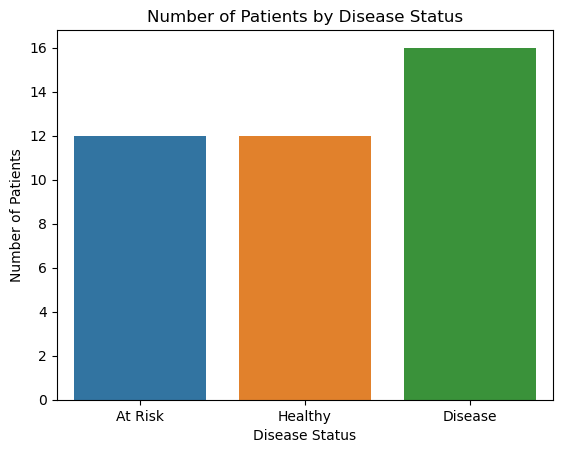

In [20]:
# 02(b)
#Create a bar chart showing the number of patients in each disease-status category.
sns.countplot(data=df,x="Disease_Status")
plt.title("Number of Patients by Disease Status")
plt.xlabel("Disease Status")
plt.ylabel("Number of Patients")
plt.show()

In [23]:
# 02(c)
#Write one observation based on the bar chart. 
highest_category = disease_counts.idxmax()
highest_count = disease_counts.max()
print(f"Observation: The '{highest_category}' group contains the highest number of patients ({highest_count}).")

Observation: The 'Disease' group contains the highest number of patients (16).


In [25]:
# 03(a)
mean_expression = df.groupby('Disease_Status')[['Gene_A_Expression', 'Gene_B_Expression', 'Gene_C_Expression']].mean()

print("Mean Gene Expression\n")
print(mean_expression)

Mean Gene Expression

                Gene_A_Expression  Gene_B_Expression  Gene_C_Expression
Disease_Status                                                         
At Risk                  5.907500           6.415833           4.177500
Disease                  7.930000           7.478000           3.940000
Healthy                  4.271667           5.912500           5.045833


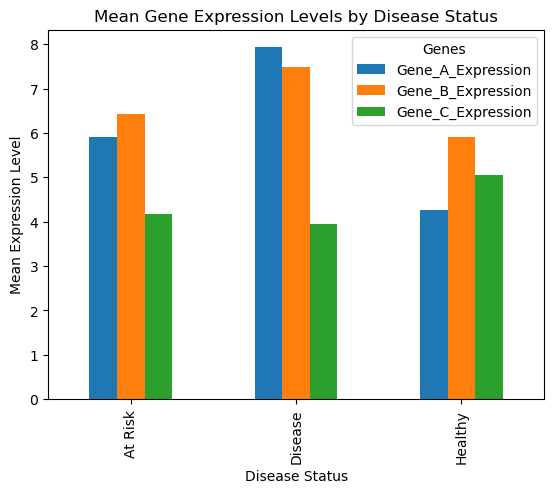

In [32]:
# 03(b)
#Create a Clustered Bar Chart
mean_expression.plot(kind='bar')

plt.title("Mean Gene Expression Levels by Disease Status")
plt.xlabel("Disease Status")
plt.ylabel("Mean Expression Level")
plt.legend(title="Genes")
plt.show()

In [33]:
# 03(c)
# Find group with highest average expression (overall mean across genes)
overall_mean = mean_expression.mean(axis=1)
highest_group = overall_mean.idxmax()

print(f"\nInterpretation:")
print(f"1. The '{highest_group}' group generally shows higher gene expression.")
print(f"2. Observation: Gene A consistently shows higher expression than Gene B and Gene C across most disease-status groups.")


Interpretation:
1. The 'Disease' group generally shows higher gene expression.
2. Observation: Gene A consistently shows higher expression than Gene B and Gene C across most disease-status groups.


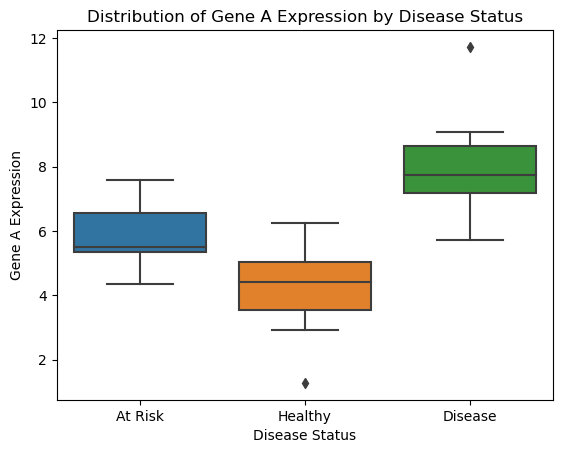

In [34]:
# 4(a) 
#Create Box Plot
sns.boxplot(x='Disease_Status', y='Gene_A_Expression', data=df)

plt.title("Distribution of Gene A Expression by Disease Status")
plt.xlabel("Disease Status")
plt.ylabel("Gene A Expression")
plt.show()

In [35]:
# 4(b) 
#Compare Median Values
median_values = df.groupby('Disease_Status')['Gene_A_Expression'].median()
highest_median_group = median_values.idxmax()
highest_median_value = median_values.max()

print(f"Median Gene A Expression by Disease Status:\n{median_values}\n")
print(f"Observation: '{highest_median_group}' group has the highest median Gene A expression ({highest_median_value:.2f}).")

Median Gene A Expression by Disease Status:
Disease_Status
At Risk    5.495
Disease    7.755
Healthy    4.415
Name: Gene_A_Expression, dtype: float64

Observation: 'Disease' group has the highest median Gene A expression (7.75).


In [38]:
# 4(c) 
for group, values in df.groupby('Disease_Status')['Gene_A_Expression']:
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = values[(values < lower) | (values > upper)]
    
    if len(outliers) > 0:
        print(f"{group}: {len(outliers)} potential outlier(s) found.")
    else:
        print(f"{group}: No potential outliers.")

At Risk: No potential outliers.
Disease: 1 potential outlier(s) found.
Healthy: 1 potential outlier(s) found.


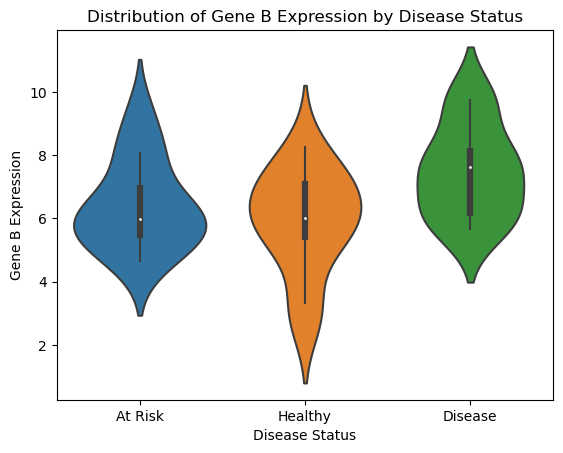

In [40]:
# 5(a)
# Create Violin Plot
sns.violinplot(x='Disease_Status', y='Gene_B_Expression', data=df)

plt.title("Distribution of Gene B Expression by Disease Status")
plt.xlabel("Disease Status")
plt.ylabel("Gene B Expression")
plt.show()

In [41]:
# 5(b) Compare Gene B Expression
median_values = df.groupby('Disease_Status')['Gene_B_Expression'].median()
highest_group = median_values.idxmax()
print(f"Observation: '{highest_group}' group generally shows higher Gene B expression.")

Observation: 'Disease' group generally shows higher Gene B expression.


In [42]:
# 5(c) Interpretation
print("\nInterpretation:")
print("- In a violin plot, the width at a given y-value represents the density of data points at that expression level.")
print("- From this plot, we can see how Gene B expression is distributed within each disease-status group, including spread, peaks, and possible multimodal patterns.")


Interpretation:
- In a violin plot, the width at a given y-value represents the density of data points at that expression level.
- From this plot, we can see how Gene B expression is distributed within each disease-status group, including spread, peaks, and possible multimodal patterns.


In [43]:
#6(a)
# a) Create Correlation Matrix
selected_vars = ['Age', 'Gene_A_Expression', 'Gene_B_Expression', 'Gene_C_Expression', 'Blood_Pressure', 'Glucose']
corr_matrix = df[selected_vars].corr()

print("Correlation Matrix:\n", corr_matrix)

Correlation Matrix:
                         Age  Gene_A_Expression  Gene_B_Expression  \
Age                1.000000          -0.025905           0.202976   
Gene_A_Expression -0.025905           1.000000           0.227354   
Gene_B_Expression  0.202976           0.227354           1.000000   
Gene_C_Expression -0.128743          -0.341759          -0.235934   
Blood_Pressure     0.827266          -0.066273           0.171765   
Glucose            0.550290           0.294534           0.241752   

                   Gene_C_Expression  Blood_Pressure   Glucose  
Age                        -0.128743        0.827266  0.550290  
Gene_A_Expression          -0.341759       -0.066273  0.294534  
Gene_B_Expression          -0.235934        0.171765  0.241752  
Gene_C_Expression           1.000000       -0.036898 -0.290527  
Blood_Pressure             -0.036898        1.000000  0.470189  
Glucose                    -0.290527        0.470189  1.000000  


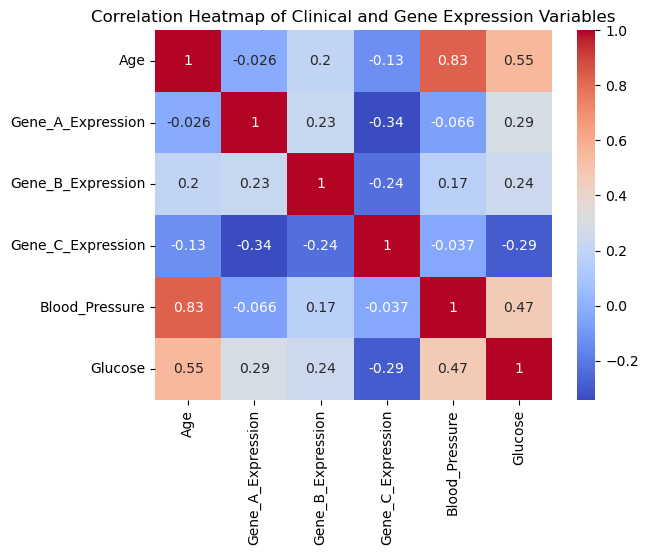

In [45]:
# 6(b) Create Heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap of Clinical and Gene Expression Variables")
plt.show()

In [46]:
# 6(c) Interpretation
# Find strongest positive correlation
corr_unstacked = corr_matrix.unstack()
corr_unstacked = corr_unstacked[corr_unstacked < 1]  # remove self-correlation
strongest_pair = corr_unstacked.idxmax()
strongest_value = corr_unstacked.max()

print(f"\nStrongest positive relationship: {strongest_pair[0]} and {strongest_pair[1]} (Correlation = {strongest_value:.2f})")
print("Interpretation: As one variable increases, the other tends to increase as well, indicating a strong positive association.")


Strongest positive relationship: Age and Blood_Pressure (Correlation = 0.83)
Interpretation: As one variable increases, the other tends to increase as well, indicating a strong positive association.


In [53]:
# 7 (a)
#Calculate Mean Expression for Disease vs Healthy
from scipy.stats import ttest_ind

# Genes to analyze
genes = ['Gene_A_Expression', 'Gene_B_Expression', 'Gene_C_Expression']

# -----------------------------
# a) Mean Expression
# -----------------------------
mean_disease = df[df['Disease_Status'] == 'Disease'][genes].mean()
mean_healthy = df[df['Disease_Status'] == 'Healthy'][genes].mean()

print("Mean Expression in Disease group:\n", mean_disease)
print("\nMean Expression in Healthy group:\n", mean_healthy)

Mean Expression in Disease group:
 Gene_A_Expression    7.930
Gene_B_Expression    7.478
Gene_C_Expression    3.940
dtype: float64

Mean Expression in Healthy group:
 Gene_A_Expression    4.271667
Gene_B_Expression    5.912500
Gene_C_Expression    5.045833
dtype: float64


In [54]:
#7(b) Log2 Fold Change

log2_fc = np.log2(mean_disease / mean_healthy)
print("\nLog2 Fold Change:\n", log2_fc)


Log2 Fold Change:
 Gene_A_Expression    0.892522
Gene_B_Expression    0.338884
Gene_C_Expression   -0.356897
dtype: float64


In [55]:
# 7(c) Statistical Significance (p-values)
p_values = {}
for gene in genes:
    disease_vals = df[df['Disease_Status'] == 'Disease'][gene]
    healthy_vals = df[df['Disease_Status'] == 'Healthy'][gene]
    _, p_val = ttest_ind(disease_vals, healthy_vals, equal_var=False)
    p_values[gene] = p_val

p_values = pd.Series(p_values)
print("\nP-values:\n", p_values)


P-values:
 Gene_A_Expression    5.648283e-07
Gene_B_Expression             NaN
Gene_C_Expression    1.502358e-02
dtype: float64


posx and posy should be finite values
posx and posy should be finite values


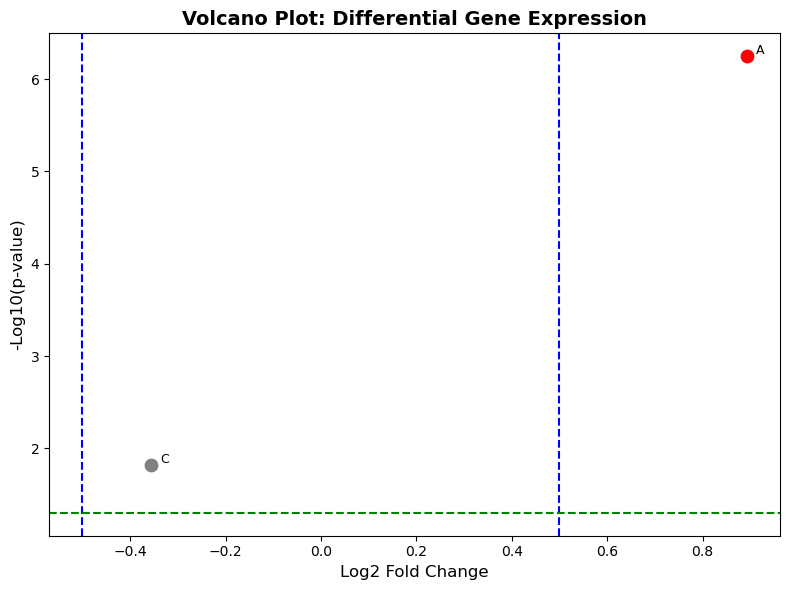

In [56]:
# 7(d) Volcano Plot
# -----------------------------
# Prepare data for plotting
volcano_df = pd.DataFrame({
    'Gene': [g.split('_')[1] for g in genes],  # Extract A, B, C
    'log2FC': log2_fc.values,
    '-log10(p-value)': -np.log10(p_values.values)
})

plt.figure(figsize=(8, 6))
plt.scatter(volcano_df['log2FC'], volcano_df['-log10(p-value)'], color='grey')

# Highlight significant points
for i, row in volcano_df.iterrows():
    color = 'red' if abs(row['log2FC']) > 0.5 and p_values[i] < 0.05 else 'grey'
    plt.scatter(row['log2FC'], row['-log10(p-value)'], color=color, s=80)
    plt.text(row['log2FC'] + 0.02, row['-log10(p-value)'] + 0.02, row['Gene'], fontsize=9)

# Threshold lines
plt.axvline(x=0.5, color='blue', linestyle='--')
plt.axvline(x=-0.5, color='blue', linestyle='--')
plt.axhline(y=-np.log10(0.05), color='green', linestyle='--')

# Labels and title
plt.title("Volcano Plot: Differential Gene Expression", fontsize=14, fontweight='bold')
plt.xlabel("Log2 Fold Change", fontsize=12)
plt.ylabel("-Log10(p-value)", fontsize=12)
plt.tight_layout()
plt.show()

In [76]:
#8(a)
try:
    import upsetplot
except ImportError:
    import sys
    !{sys.executable} -m pip install upsetplot
    import upsetplot

mutation_cols = ['Mutation_A', 'Mutation_B', 'Mutation_C']

# Convert Yes/No to Boolean (True/False)
df_bool = df[mutation_cols].applymap(lambda x: True if str(x).strip().lower() == 'yes' else False)

print("Boolean Mutation Data:\n", df_bool.head())

Boolean Mutation Data:
    Mutation_A  Mutation_B  Mutation_C
0        True        True        True
1       False        True       False
2       False        True       False
3        True        True       False
4        True       False       False


ValueError: If indicators.index is not the default, all its values must be present in data.index

In [74]:
# 8(b) Create UpSet Plot
upset_data = from_indicators(df_bool, mutation_cols)
UpSet(upset_data, subset_size='count', show_counts=True).plot()
plt.suptitle("UpSet Plot: Mutation Intersections")
plt.show()

ValueError: If indicators.index is not the default, all its values must be present in data.index

In [75]:
# 8(c) Identify the Most Common Combination
combination_counts = upset_data.value_counts()
most_common_combo = combination_counts.idxmax()
most_common_count = combination_counts.max()

print(f"\nMost Common Combination: {most_common_combo} ({most_common_count} samples)")

NameError: name 'upset_data' is not defined

In [67]:
# 8(d) Interpretation
print("\nInterpretation:")
print("- An UpSet plot is more useful than a Venn diagram when analyzing more than 3 sets,")
print("  because it clearly shows all intersections and their sizes without overlapping shapes.")
print("- It scales better for complex biological datasets, making it easier to spot rare or common mutation patterns.")


Interpretation:
- An UpSet plot is more useful than a Venn diagram when analyzing more than 3 sets,
  because it clearly shows all intersections and their sizes without overlapping shapes.
- It scales better for complex biological datasets, making it easier to spot rare or common mutation patterns.
